In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Import libraries
import pandas as pd
import numpy as np
import json
import re
import math

from pathlib import Path
from transformers import AutoTokenizer

In [3]:

from pathlib import Path
from transformers import AutoTokenizer

# Main project folder
PROJECT_DIR = Path("/content/drive/MyDrive/NLP Project")

# Input: output produced by preprocessing.ipynb
INPUT_FILE = (
    PROJECT_DIR / "data" / "preprocessed_text"
    / "preprocessed_pages.jsonl"
)

# Folder to save chunking results
CHUNK_DIR = PROJECT_DIR / "data" / "chunks" / "bge_small"
CHUNK_DIR.mkdir(parents=True, exist_ok=True)

# Chunking parameters
CHUNK_SIZE = 500       # Maximum target size in tokens
CHUNK_OVERLAP = 80     # Overlapping tokens between chunks

# Embedding model and tokenizer
MODEL_NAME = "BAAI/bge-small-en-v1.5"
MODEL_MAX_TOKENS = 512

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=True
)

# Check special tokens
SPECIAL_TOKENS = tokenizer.num_special_tokens_to_add(
    pair=False
)

# Validate chunking configuration
assert CHUNK_SIZE + SPECIAL_TOKENS <= MODEL_MAX_TOKENS, (
    "Chunk size exceeds the embedding model's input limit."
)

assert 0 <= CHUNK_OVERLAP < CHUNK_SIZE

print("Tokenizer loaded successfully.")
print("Model:", MODEL_NAME)
print("Model maximum tokens:", MODEL_MAX_TOKENS)
print("Chunk size:", CHUNK_SIZE)
print("Chunk overlap:", CHUNK_OVERLAP)
print("Special tokens:", SPECIAL_TOKENS)
print("Input file exists:", INPUT_FILE.exists())
print("Output directory:", CHUNK_DIR)


config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/366 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

Tokenizer loaded successfully.
Model: BAAI/bge-small-en-v1.5
Model maximum tokens: 512
Chunk size: 500
Chunk overlap: 80
Special tokens: 2
Input file exists: True
Output directory: /content/drive/MyDrive/NLP Project/data/chunks/bge_small


In [4]:
# Load the preprocessed page records
pages_df = pd.read_json(INPUT_FILE, lines=True)

# Check that the required columns are available
required_columns = {
    'article_id',
    'page_number',
    'clean_text',
    'keep_for_index'
}

missing_columns = required_columns - set(pages_df.columns)

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Keep only pages approved for indexing
pages_df = pages_df[
    pages_df['keep_for_index'].fillna(False).astype(bool)
].copy()

# Remove empty pages
pages_df['clean_text'] = pages_df['clean_text'].fillna('').astype(str)

pages_df = pages_df[
    pages_df['clean_text'].str.strip() != ''
].copy()

# Sort pages by article and page number
pages_df['_page_sort'] = pd.to_numeric(
    pages_df['page_number'],
    errors='coerce'
)

pages_df = pages_df.sort_values(
    ['article_id', '_page_sort', 'page_number'],
    kind='stable'
).reset_index(drop=True)

print("Eligible pages:", len(pages_df))
print("Articles:", pages_df['article_id'].nunique())

pages_df.head()

Eligible pages: 3226
Articles: 180


,article_id,title,year,page_number,page_label,clean_text,n_words,bad_chars,status,reference_method,reference_review,drop_reason,keep_for_index,duplicate_of,_page_sort
0,FD_001,Credit card fraud detection in the era of disr...,2023,1,145,Credit card fraud detection in the era of disr...,420,0,body,heading_with_citation_evidence,False,,True,None,1
1,FD_001,Credit card fraud detection in the era of disr...,2023,2,146,3.5.\n3.6.\n3.7.\n3.8.\n4.\n4.1.\n4.2.\n5.\n6....,590,0,body,heading_with_citation_evidence,False,,True,None,2
2,FD_001,Credit card fraud detection in the era of disr...,2023,3,147,detection. We also aim to review recent work p...,847,0,body,heading_with_citation_evidence,False,,True,None,3
3,FD_001,Credit card fraud detection in the era of disr...,2023,4,148,"However, some papers were too old and no compa...",381,0,body,heading_with_citation_evidence,False,,True,None,4
4,FD_001,Credit card fraud detection in the era of disr...,2023,5,149,Fig. 2. Papers distribution according to the p...,260,0,body,heading_with_citation_evidence,False,,True,None,5


In [5]:
def build_article_text(group):
    """
    Combine all eligible pages of one article.

    Also record the character positions belonging to each page.
    These positions will help us trace chunks back to original pages.
    """

    full_text = ""
    page_spans = []

    for _, row in group.iterrows():

        page_text = str(row['clean_text']).strip()

        if not page_text:
            continue

        # Add a newline between pages
        if full_text:
            full_text += "\n\n"

        # Record where this page starts
        start_position = len(full_text)

        # Add the page content
        full_text += page_text

        # Record where this page ends
        end_position = len(full_text)

        page_spans.append({
            'page_number': row['page_number'],
            'start': start_position,
            'end': end_position
        })

    return full_text, page_spans

In [6]:
def get_article_metadata(group):
    """
    Extract metadata from the first page record of an article.
    Missing metadata is represented by an empty string.
    """

    first = group.iloc[0]

    metadata_fields = [
        'article_id',
        'title',
        'authors',
        'year',
        'venue',
        'doi'
    ]

    metadata = {}

    for field in metadata_fields:

        if field in group.columns:
            value = first[field]

            # Replace missing values with an empty string
            if pd.isna(value):
                value = ''

            metadata[field] = value

        else:
            metadata[field] = ''

    return metadata

In [7]:
def make_chunk(
    text,
    start_char,
    end_char,
    page_spans,
    metadata,
    strategy,
    token_count
):
    """
    Create one chunk with its text and source metadata.

    start_char and end_char refer to positions in the combined article text.
    """

    # Find the original pages that overlap with this chunk
    covered_pages = []

    for page in page_spans:

        # Check whether the chunk overlaps with this page
        overlaps = (
            start_char < page['end']
            and end_char > page['start']
        )

        if overlaps:
            covered_pages.append(page['page_number'])

    # Create a record for the chunk
    chunk = metadata.copy()

    chunk.update({
        'text': text.strip(),
        'start_page': covered_pages[0] if covered_pages else None,
        'end_page': covered_pages[-1] if covered_pages else None,
        'page_numbers': covered_pages,
        'start_char': start_char,
        'end_char': end_char,
        'token_count': token_count,
        'chunking_strategy': strategy
    })

    return chunk

**Fixed-size chunking with overlap**

In [8]:

def fixed_size_chunking(
    text,
    page_spans,
    metadata,
    chunk_size=CHUNK_SIZE,
    overlap=CHUNK_OVERLAP
):
    """
    Split article text into fixed-size token chunks.

    Features:
    - Token-based chunking
    - Configurable overlap
    - Character-offset preservation
    - Page-level source tracking
    - Empty-text and parameter validation
    """

    # Validate parameters
    if chunk_size <= 0:
        raise ValueError("chunk_size must be positive.")

    if not 0 <= overlap < chunk_size:
        raise ValueError(
            "overlap must be >= 0 and smaller than chunk_size."
        )

    if not text or not text.strip():
        return []

    # Tokenize the article and obtain character offsets
    token_ids, offsets = get_token_offsets(text)

    if not token_ids:
        return []

    chunks = []
    start_token = 0
    total_tokens = len(token_ids)

    while start_token < total_tokens:

        # Determine token boundaries
        end_token = min(
            start_token + chunk_size,
            total_tokens
        )

        # Convert token positions into character positions
        start_char = offsets[start_token][0]
        end_char = offsets[end_token - 1][1]

        # Extract the original text
        chunk_text = text[start_char:end_char]

        if chunk_text.strip():

            chunk = make_chunk(
                text=chunk_text,
                start_char=start_char,
                end_char=end_char,
                page_spans=page_spans,
                metadata=metadata,
                strategy="fixed_size",
                token_count=end_token - start_token
            )

            chunks.append(chunk)

        # Stop when the final token is processed
        if end_token == total_tokens:
            break

        # Move forward while retaining overlap
        start_token = end_token - overlap

    return chunks


**Sentence-based chunking**

In [9]:

import re

def sentence_based_chunking(
    text,
    page_spans,
    metadata,
    chunk_size=CHUNK_SIZE,
    overlap=CHUNK_OVERLAP
):
    """
    Split an article into sentence-based chunks.

    Features:
    - Preserve complete sentences when possible.
    - Split oversized sentences into token windows.
    - Retain whole-sentence overlap when possible.
    - Enforce the model's maximum input length.
    - Preserve character positions and page metadata.
    """

    if chunk_size <= 0:
        raise ValueError("chunk_size must be positive.")

    if not 0 <= overlap < chunk_size:
        raise ValueError(
            "overlap must be smaller than chunk_size."
        )

    if not text or not text.strip():
        return []

    # Reserve space for model special tokens.
    special_tokens = tokenizer.num_special_tokens_to_add(
        pair=False
    )

    max_content_tokens = min(
        chunk_size,
        MODEL_MAX_TOKENS - special_tokens
    )

    if max_content_tokens <= 0:
        raise ValueError("Invalid model token limit.")

    chunks = []

    def count_tokens(value):
        return len(
            tokenizer.encode(
                value,
                add_special_tokens=False
            )
        )

    def add_chunk(start, end):
        """Save a chunk with accurate offsets."""

        # Remove surrounding whitespace while updating offsets.
        raw = text[start:end]
        left = len(raw) - len(raw.lstrip())
        right = len(raw.rstrip())

        start = start + left
        end = start - left + right

        if start >= end:
            return

        chunk_text = text[start:end]

        token_count = count_tokens(chunk_text)

        actual_length = len(
            tokenizer.encode(
                chunk_text,
                add_special_tokens=True
            )
        )

        if (
            token_count > max_content_tokens
            or actual_length > MODEL_MAX_TOKENS
        ):
            raise ValueError(
                f"Chunk exceeds token limit: "
                f"{actual_length} tokens"
            )

        chunks.append(
            make_chunk(
                text=chunk_text,
                start_char=start,
                end_char=end,
                page_spans=page_spans,
                metadata=metadata,
                strategy="sentence_based",
                token_count=token_count
            )
        )

    # Step 1: Identify sentence boundaries

    sentence_pattern = re.compile(
        r"(?<=[.!?])\s+|\n{2,}"
    )

    sentence_spans = []
    previous_end = 0

    def record_sentence(start, end):
        raw = text[start:end]

        left = len(raw) - len(raw.lstrip())
        right = len(raw.rstrip())

        if right > left:
            sentence_spans.append(
                (start + left, start + right)
            )

    for match in sentence_pattern.finditer(text):
        record_sentence(previous_end, match.start())
        previous_end = match.end()

    record_sentence(previous_end, len(text))

    # Step 2: Group sentences within the token limit

    current_group = []

    for sentence_index, (start, end) in enumerate(
        sentence_spans
    ):

        sentence_text = text[start:end]
        sentence_tokens = count_tokens(sentence_text)

        # Case A: Oversized sentence

        if sentence_tokens > max_content_tokens:

            # Save the current sentence group.
            if current_group:
                group_start = sentence_spans[
                    current_group[0]
                ][0]

                group_end = sentence_spans[
                    current_group[-1]
                ][1]

                add_chunk(group_start, group_end)
                current_group = []

            # Split long sentences using token offsets.
            token_ids, offsets = get_token_offsets(
                sentence_text
            )

            start_token = 0

            while start_token < len(token_ids):

                end_token = min(
                    start_token + max_content_tokens,
                    len(token_ids)
                )

                # Adjust the end until the passage fits.
                while end_token > start_token:

                    local_start = offsets[
                        start_token
                    ][0]

                    local_end = offsets[
                        end_token - 1
                    ][1]

                    absolute_start = start + local_start
                    absolute_end = start + local_end

                    candidate = text[
                        absolute_start:absolute_end
                    ]

                    if (
                        count_tokens(candidate)
                        <= max_content_tokens
                        and len(
                            tokenizer.encode(
                                candidate,
                                add_special_tokens=True
                            )
                        ) <= MODEL_MAX_TOKENS
                    ):
                        break

                    end_token -= 1

                if end_token == start_token:
                    raise ValueError(
                        "Unable to split oversized sentence."
                    )

                add_chunk(
                    absolute_start,
                    absolute_end
                )

                if end_token == len(token_ids):
                    break

                # Keep token overlap and ensure progress.
                start_token = max(
                    start_token + 1,
                    end_token - overlap
                )

            continue

        # Case B: Sentence fits within the limit

        if current_group:

            group_start = sentence_spans[
                current_group[0]
            ][0]

            candidate_text = text[group_start:end]

            if (
                count_tokens(candidate_text)
                > max_content_tokens
            ):

                # Save the completed group.
                group_end = sentence_spans[
                    current_group[-1]
                ][1]

                add_chunk(group_start, group_end)

                # Retain trailing complete sentences
                # without exceeding the overlap budget.
                retained = []

                for old_index in reversed(current_group):

                    old_start = sentence_spans[
                        old_index
                    ][0]

                    overlap_text = text[
                        old_start:group_end
                    ]

                    combined_text = text[
                        old_start:end
                    ]

                    if (
                        count_tokens(overlap_text) > overlap
                        or count_tokens(combined_text)
                        > max_content_tokens
                    ):
                        break

                    retained.insert(0, old_index)

                current_group = retained

        # Add the current sentence.
        current_group.append(sentence_index)

    # Step 3: Save the remaining sentences

    if current_group:

        group_start = sentence_spans[
            current_group[0]
        ][0]

        group_end = sentence_spans[
            current_group[-1]
        ][1]

        add_chunk(group_start, group_end)

    return chunks


**Recursive chunking**

In [10]:

from bisect import bisect_right

def recursive_chunking(
    text,
    page_spans,
    metadata,
    chunk_size=CHUNK_SIZE,
    overlap=CHUNK_OVERLAP
):
    """
    Boundary-aware token chunking.

    Prefers natural text boundaries:
    1. Paragraphs
    2. Newlines
    3. Sentences
    4. Spaces

    Preserves overlap, character offsets, and page metadata.
    """

    # Validate parameters
    if chunk_size <= 0:
        raise ValueError("Chunk size must be positive.")

    if not 0 <= overlap < chunk_size:
        raise ValueError(
            "Overlap must be >= 0 and smaller than chunk size."
        )

    if not text or not text.strip():
        return []

    # Account for model special tokens
    special_tokens = tokenizer.num_special_tokens_to_add(
        pair=False
    )

    max_content_tokens = min(
        chunk_size,
        MODEL_MAX_TOKENS - special_tokens
    )

    if max_content_tokens <= overlap:
        raise ValueError(
            "Overlap is too large for the model token limit."
        )

    # Tokenize article and obtain character offsets
    token_ids, offsets = get_token_offsets(text)

    if not token_ids:
        return []

    chunks = []
    total_tokens = len(token_ids)

    # Token end positions for efficient boundary lookup
    token_ends = [end for _, end in offsets]

    # Preferred text boundaries
    separators = [
        "\n\n",
        "\n",
        ". ",
        "? ",
        "! ",
        " "
    ]

    start_token = 0

    while start_token < total_tokens:

        # Maximum token window
        max_end_token = min(
            start_token + max_content_tokens,
            total_tokens
        )

        end_token = max_end_token

        # Look for natural boundaries unless this is
        # the final token window.
        if max_end_token < total_tokens:

            start_char = offsets[start_token][0]
            max_end_char = offsets[max_end_token - 1][1]

            candidate_text = text[start_char:max_end_char]

            # Search within the final 35% of the window.
            # This avoids unnecessarily small chunks.
            search_start = int(
                len(candidate_text) * 0.65
            )

            for separator in separators:

                position = candidate_text.rfind(
                    separator,
                    search_start
                )

                if position == -1:
                    continue

                boundary_char = (
                    start_char
                    + position
                    + len(separator)
                )

                # Find the number of tokens ending
                # at or before the selected boundary.
                adjusted_end = bisect_right(
                    token_ends,
                    boundary_char,
                    lo=start_token,
                    hi=max_end_token
                )

                # Keep enough tokens for meaningful
                # content and safe overlap.
                if adjusted_end - start_token > overlap:
                    end_token = adjusted_end
                    break

        # Validate the actual chunk text against
        # the embedding model token limit.
        while end_token > start_token:

            start_char = offsets[start_token][0]
            end_char = offsets[end_token - 1][1]

            chunk_text = text[start_char:end_char]

            actual_length = len(
                tokenizer.encode(
                    chunk_text,
                    add_special_tokens=True,
                    truncation=False
                )
            )

            if actual_length <= MODEL_MAX_TOKENS:
                break

            # Reduce window if necessary
            end_token -= 1

        if end_token <= start_token:
            raise ValueError(
                "Unable to create a valid chunk."
            )

        if chunk_text.strip():

            content_tokens = len(
                tokenizer.encode(
                    chunk_text,
                    add_special_tokens=False,
                    truncation=False
                )
            )

            chunk = make_chunk(
                text=chunk_text,
                start_char=start_char,
                end_char=end_char,
                page_spans=page_spans,
                metadata=metadata,
                strategy="recursive",
                token_count=content_tokens
            )

            chunks.append(chunk)

        # Finish after processing all article tokens
        if end_token == total_tokens:
            break

        # Preserve overlap when possible
        next_start = end_token - overlap

        # Ensure forward progress
        if next_start <= start_token:
            next_start = end_token

        start_token = next_start

    return chunks


**Section-aware chunking**

In [11]:

import re

# 1. COMMON ACADEMIC SECTION HEADINGS

SECTION_NAMES = {
    "abstract",
    "introduction",
    "background",
    "related work",
    "related works",
    "literature review",
    "methodology",
    "methods",
    "materials and methods",
    "materials & methods",
    "data and methods",
    "proposed method",
    "proposed approach",
    "proposed framework",
    "model architecture",
    "research methodology",
    "data collection",
    "dataset description",
    "datasets",
    "data preprocessing",
    "feature engineering",
    "feature selection",
    "classification models",
    "experimental setup",
    "experimental settings",
    "experimental evaluation",
    "experiments",
    "implementation details",
    "results",
    "experimental results",
    "findings",
    "discussion",
    "results and discussion",
    "performance evaluation",
    "evaluation metrics",
    "comparative analysis",
    "ablation study",
    "conclusion",
    "conclusions",
    "concluding remarks",
    "future work",
    "limitations",
    "research limitations",
    "implications",
    "threats to validity",
    "acknowledgments",
    "acknowledgements",
    "data availability",
    "data availability statement"
}


# 2. SECTION HEADING DETECTION

NUMBERED_HEADING_PATTERN = re.compile(
    r"^(?:\d{1,2}(?:\.\d{1,2}){0,3}|[IVX]{1,6})"
    r"[.)]?\s+(.+)$",
    flags=re.I
)


def is_section_heading(line):
    """
    Identify likely academic section headings.

    Supports:
    - Introduction
    - 1. Introduction
    - 2.3 Proposed Framework
    - IV. Experimental Results

    Uses conservative rules to reduce false positives
    from tables, figures and PDF extraction artifacts.
    """

    line = re.sub(r"\s+", " ", str(line)).strip()

    if not line or len(line) > 100:
        return False

    # Exclude figure, table and equation captions.
    if re.match(
        r"^(figure|fig\.?|table|algorithm|equation)"
        r"\s*\d+",
        line,
        flags=re.I
    ):
        return False

    # Exclude URLs and DOI references.
    if re.match(
        r"^(https?://|doi:)",
        line,
        flags=re.I
    ):
        return False

    # Detect numbered headings.
    numbered = NUMBERED_HEADING_PATTERN.match(line)

    if numbered:
        heading_text = numbered.group(1).strip()
    else:
        heading_text = line

    normalized = heading_text.lower().rstrip(" :.")

    # Recognize standard academic section names.
    if normalized in SECTION_NAMES:
        return True

    # Unknown headings must have section numbering.
    if numbered is None:
        return False

    words = heading_text.split()

    # Reject very short or very long candidates.
    if not 2 <= len(words) <= 10:
        return False

    if len(heading_text) > 80:
        return False

    # Reject sentence-like endings.
    if heading_text.endswith((".", ";", ",")):
        return False

    # Require title-like capitalization.
    if not heading_text[0].isupper():
        return False

    return True


# 3. SPLIT ARTICLE INTO SECTIONS

def split_into_sections(text):
    """
    Split an article into academic sections.

    Each section retains:
    - Section heading
    - Section text
    - Original start character
    - Original end character

    Character positions remain relative to the
    complete article text.
    """

    if not text or not text.strip():
        return []

    headings = []
    position = 0

    # Identify heading positions.
    for line in text.splitlines(keepends=True):

        heading = line.strip()

        if is_section_heading(heading):
            headings.append({
                "section": heading,
                "start": position
            })

        position += len(line)

    # If no section heading is detected,
    # treat the whole article as one section.
    if not headings:
        return [{
            "section": "Unsectioned",
            "text": text,
            "start": 0,
            "end": len(text)
        }]

    boundaries = []

    # Preserve content before the first heading.
    if headings[0]["start"] > 0:
        boundaries.append({
            "section": "Unsectioned",
            "start": 0
        })

    boundaries.extend(headings)

    sections = []

    # Extract each section using exact character spans.
    for i, boundary in enumerate(boundaries):

        start = boundary["start"]

        if i + 1 < len(boundaries):
            end = boundaries[i + 1]["start"]
        else:
            end = len(text)

        section_text = text[start:end]

        if not section_text.strip():
            continue

        sections.append({
            "section": boundary["section"],
            "text": section_text,
            "start": start,
            "end": end
        })

    return sections


# 4. SECTION-AWARE CHUNKING

def section_aware_chunking(
    text,
    page_spans,
    metadata,
    chunk_size=CHUNK_SIZE,
    overlap=CHUNK_OVERLAP
):
    """
    Perform section-aware chunking.

    Steps:
    1. Identify academic sections.
    2. Apply boundary-aware recursive-style chunking
       independently within each section.
    3. Restore original article character offsets.
    4. Preserve article and page-level metadata.
    5. Validate token lengths for the embedding model.

    Chunks from different sections are not combined.
    """

    # Validate inputs

    if not text or not text.strip():
        return []

    if chunk_size <= 0:
        raise ValueError("Chunk size must be positive.")

    if not 0 <= overlap < chunk_size:
        raise ValueError(
            "Overlap must be nonnegative "
            "and smaller than chunk size."
        )

    # Detect sections

    sections = split_into_sections(text)

    chunks = []

    # Process each section independently

    for section in sections:

        section_text = section["text"]
        section_start = section["start"]

        # Generate section-local chunks.
        # Page mapping will be restored using
        # the original article page spans.
        local_chunks = recursive_chunking(
            text=section_text,
            page_spans=[],
            metadata=metadata,
            chunk_size=chunk_size,
            overlap=overlap
        )

        # Restore original character positions

        for local_chunk in local_chunks:

            absolute_start = (
                section_start + local_chunk["start_char"]
            )

            absolute_end = (
                section_start + local_chunk["end_char"]
            )

            # Trim surrounding whitespace while keeping
            # character offsets synchronized.
            raw_text = text[absolute_start:absolute_end]

            left_trim = (
                len(raw_text) - len(raw_text.lstrip())
            )

            right_length = len(raw_text.rstrip())

            clean_start = absolute_start + left_trim
            clean_end = absolute_start + right_length

            if clean_start >= clean_end:
                continue

            chunk_text = text[clean_start:clean_end]

            # Validate token count

            content_tokens = len(
                tokenizer.encode(
                    chunk_text,
                    add_special_tokens=False,
                    truncation=False
                )
            )

            model_tokens = len(
                tokenizer.encode(
                    chunk_text,
                    add_special_tokens=True,
                    truncation=False
                )
            )

            if model_tokens > MODEL_MAX_TOKENS:
                raise ValueError(
                    f"Chunk exceeds model limit: "
                    f"{model_tokens} tokens. "
                    f"Article: {metadata['article_id']}"
                )

            # Create chunk using original article metadata

            chunk = make_chunk(
                text=chunk_text,
                start_char=clean_start,
                end_char=clean_end,
                page_spans=page_spans,
                metadata=metadata,
                strategy="section_aware",
                token_count=content_tokens
            )

            # Add section information.
            chunk["section"] = section["section"]

            # Record the model-specific token count.
            chunk["model_token_count"] = model_tokens

            # Validate character and page references

            if text[clean_start:clean_end] != chunk["text"]:
                raise ValueError(
                    "Chunk text and character offsets "
                    "do not match."
                )

            if not chunk["page_numbers"]:
                raise ValueError(
                    "Missing page mapping for article: "
                    f"{metadata['article_id']}"
                )

            chunks.append(chunk)

    return chunks


print("Section-aware chunking functions loaded successfully.")


Section-aware chunking functions loaded successfully.


In [12]:

# 1. TOKENIZATION WITH CHARACTER OFFSETS

def get_token_offsets(text):
    """
    Tokenize text and return token IDs and character offsets.

    Truncation is disabled because full research articles
    must be processed before being divided into chunks.
    """

    if not text or not text.strip():
        return [], []

    encoding = tokenizer(
        text,
        add_special_tokens=False,
        return_offsets_mapping=True,
        truncation=False
    )

    return (
        encoding["input_ids"],
        encoding["offset_mapping"]
    )


# 2. PROCESSING CONFIGURATION

# Use 10 for initial testing.
# Change to None to process all research articles.
MAX_ARTICLES = None

# Store chunks from each strategy.
all_chunks = {
    "fixed_size": [],
    "sentence_based": [],
    "recursive": [],
    "section_aware": []
}

# Group preprocessed pages by article.
article_groups = list(
    pages_df.groupby("article_id", sort=False)
)

if MAX_ARTICLES is not None:
    article_groups = article_groups[:MAX_ARTICLES]

print("Articles selected:", len(article_groups))
print("Tokenizer:", MODEL_NAME)
print("Chunk size:", CHUNK_SIZE)
print("Chunk overlap:", CHUNK_OVERLAP)


# 3. CHUNK VALIDATION HELPER

def check_generated_chunks(chunks, article_id, strategy):
    """
    Validate article references, page mappings,
    and token lengths before saving chunks.
    """

    for chunk in chunks:

        # Verify article identity.
        if chunk["article_id"] != article_id:
            raise ValueError(
                f"Incorrect article ID: {article_id}"
            )

        # Verify source-page mapping.
        if not chunk.get("page_numbers"):
            raise ValueError(
                f"Missing page mapping: "
                f"{article_id}, {strategy}"
            )

        # Verify nonempty content.
        if not chunk["text"].strip():
            raise ValueError(
                f"Empty chunk: {article_id}, {strategy}"
            )

        # Count tokens using the selected model tokenizer.
        actual_tokens = len(
            tokenizer.encode(
                chunk["text"],
                add_special_tokens=True,
                truncation=False
            )
        )

        chunk["model_token_count"] = actual_tokens

        if actual_tokens > MODEL_MAX_TOKENS:
            raise ValueError(
                f"Oversized chunk in {article_id} "
                f"({strategy}): {actual_tokens} tokens"
            )


# 4. GENERATE CHUNKS

for article_number, (article_id, group) in enumerate(
    article_groups,
    start=1
):

    print(
        f"Processing {article_number}/"
        f"{len(article_groups)}: {article_id}"
    )

    # Sort pages in document order.
    group = group.sort_values(
        "_page_sort",
        kind="stable"
    ).reset_index(drop=True)

    # Combine article pages and track page spans.
    article_text, page_spans = build_article_text(group)

    # Retrieve available article metadata.
    metadata = get_article_metadata(group)

    if not article_text.strip():
        print("Skipping empty article:", article_id)
        continue

    # Generate all four chunking strategies.
    generated = {
        "fixed_size": fixed_size_chunking(
            article_text,
            page_spans,
            metadata
        ),

        "sentence_based": sentence_based_chunking(
            article_text,
            page_spans,
            metadata
        ),

        "recursive": recursive_chunking(
            article_text,
            page_spans,
            metadata
        ),

        "section_aware": section_aware_chunking(
            article_text,
            page_spans,
            metadata
        )
    }

    # Validate each strategy before storing its chunks.
    for strategy, strategy_chunks in generated.items():

        check_generated_chunks(
            strategy_chunks,
            article_id,
            strategy
        )

        all_chunks[strategy].extend(strategy_chunks)


# 5. FINAL SUMMARY

print("\n" + "=" * 60)
print("CHUNKING COMPLETED")
print("=" * 60)

for strategy, strategy_chunks in all_chunks.items():

    unique_articles = len({
        chunk["article_id"]
        for chunk in strategy_chunks
    })

    max_tokens = max(
        (
            chunk["model_token_count"]
            for chunk in strategy_chunks
        ),
        default=0
    )

    print(f"\nStrategy: {strategy}")
    print("Total chunks:", len(strategy_chunks))
    print("Unique articles:", unique_articles)
    print("Maximum model tokens:", max_tokens)

print("\nAll generated chunks passed validation.")


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (28614 > 512). Running this sequence through the model will result in indexing errors


Articles selected: 180
Tokenizer: BAAI/bge-small-en-v1.5
Chunk size: 500
Chunk overlap: 80
Processing 1/180: FD_001
Processing 2/180: FD_002
Processing 3/180: FD_003
Processing 4/180: FD_004
Processing 5/180: FD_005
Processing 6/180: FD_006
Processing 7/180: FD_007
Processing 8/180: FD_008
Processing 9/180: FD_009
Processing 10/180: FD_010
Processing 11/180: FD_011
Processing 12/180: FD_012
Processing 13/180: FD_013
Processing 14/180: FD_014
Processing 15/180: FD_015
Processing 16/180: FD_016
Processing 17/180: FD_017
Processing 18/180: FD_018
Processing 19/180: FD_019
Processing 20/180: FD_020
Processing 21/180: FD_021
Processing 22/180: FD_022
Processing 23/180: FD_023
Processing 24/180: FD_024
Processing 25/180: FD_025
Processing 26/180: FD_026
Processing 27/180: FD_027
Processing 28/180: FD_028
Processing 29/180: FD_029
Processing 30/180: FD_030
Processing 31/180: FD_031
Processing 32/180: FD_032
Processing 33/180: FD_033
Processing 34/180: FD_034
Processing 35/180: FD_035
Processi

In [13]:

# ASSIGN UNIQUE CHUNK IDS AND STRATEGY METADATA

for strategy, chunks in all_chunks.items():

    for number, chunk in enumerate(chunks, start=1):

        # Assign unique IDs for each chunking strategy.
        # Example: recursive_00001
        chunk["chunk_id"] = f"{strategy}_{number:05d}"

        # Ensure the strategy name is recorded.
        chunk["chunking_strategy"] = strategy

        # Preserve detected section names.
        # Use an empty string for non-section-aware chunks.
        if "section" not in chunk:
            chunk["section"] = ""

# VALIDATE CHUNK ID UNIQUENESS

for strategy, chunks in all_chunks.items():

    chunk_ids = [chunk["chunk_id"] for chunk in chunks]

    assert len(chunk_ids) == len(set(chunk_ids)), (
        f"Duplicate chunk IDs found in {strategy}"
    )

    print(
        f"{strategy}: {len(chunk_ids)} unique chunk IDs"
    )

print("\nChunk ID assignment completed successfully.")


fixed_size: 5703 unique chunk IDs
sentence_based: 5839 unique chunk IDs
recursive: 6106 unique chunk IDs
section_aware: 7623 unique chunk IDs

Chunk ID assignment completed successfully.


In [14]:

# FIX TOKEN COUNT MISMATCHES IN FIXED-SIZE CHUNKS

fixed_chunks = all_chunks["fixed_size"]

corrected = 0

for chunk in fixed_chunks:

    # Recalculate actual content tokens
    actual_content_tokens = len(
        tokenizer.encode(
            chunk["text"],
            add_special_tokens=False,
            truncation=False
        )
    )

    # Recalculate tokens including special tokens
    actual_model_tokens = len(
        tokenizer.encode(
            chunk["text"],
            add_special_tokens=True,
            truncation=False
        )
    )

    # Count metadata mismatches
    if chunk["token_count"] != actual_content_tokens:
        corrected += 1

    # Update token counts
    chunk["token_count"] = actual_content_tokens
    chunk["model_token_count"] = actual_model_tokens

    # Check BGE model limit
    if actual_model_tokens > MODEL_MAX_TOKENS:
        raise ValueError(
            f"Chunk {chunk['chunk_id']} exceeds "
            f"{MODEL_MAX_TOKENS} tokens."
        )

print("Token count correction completed.")
print("Corrected chunks:", corrected)
print("Total fixed-size chunks:", len(fixed_chunks))
print("All fixed-size chunks are within model limits.")


Token count correction completed.
Corrected chunks: 163
Total fixed-size chunks: 5703
All fixed-size chunks are within model limits.


In [15]:

# DISPLAY SAMPLE CHUNKS FROM ALL FOUR STRATEGIES

NUM_SAMPLES = 3        # Number of chunks per strategy
TEXT_PREVIEW = 1000    # Maximum characters to display

for strategy, chunks in all_chunks.items():

    print("\n" + "#" * 90)
    print(f"CHUNKING STRATEGY: {strategy.upper()}")
    print(f"Total chunks: {len(chunks)}")
    print("#" * 90)

    # Display first three chunks of each strategy
    for chunk in chunks[:NUM_SAMPLES]:

        print("\n" + "=" * 80)

        print("Chunk ID:", chunk["chunk_id"])
        print("Article ID:", chunk["article_id"])
        print("Title:", chunk.get("title", "N/A"))
        print("Year:", chunk.get("year", "N/A"))
        print("Pages:", chunk["page_numbers"])
        print("Section:", chunk.get("section", "N/A"))
        print("Token count:", chunk["token_count"])
        print(
            "Model token count:",
            chunk.get("model_token_count", "N/A")
        )

        print("\nCHUNK TEXT:")
        print(chunk["text"][:TEXT_PREVIEW])

        print("=" * 80)

print("\nAll chunking strategies inspected successfully.")



##########################################################################################
CHUNKING STRATEGY: FIXED_SIZE
Total chunks: 5703
##########################################################################################

Chunk ID: fixed_size_00001
Article ID: FD_001
Title: Credit card fraud detection in the era of disruptive technologies, A systematic review.
Year: 2023
Pages: [1]
Section: 
Token count: 500
Model token count: 502

CHUNK TEXT:
Credit card fraud detection in the era of disruptive technologies:
A systematic review
Asma Cherif a,b, Arwa Badhib a, Heyfa Ammar b,c, Suhair Alshehri a, Manal Kalkatawi a, Abdessamad Imine d
a Department of Information Technology, Faculty of Computing & Information Technology, King Abdulaziz University, Jeddah, Saudi Arabia
b Center of Excellence in Smart Environment Research, King Abdulaziz University, Jeddah, Saudi Arabia
c RISC-ENIT Research Lab, National Engineering School of Tunis, Universty of Almanar, Tunisia
d Lorraine Univer

In [16]:

# FINAL CHUNK VALIDATION FOR ALL FOUR STRATEGIES

MODEL_MAX_TOKENS = 512

def validate_chunks(chunks, strategy_name):
    """
    Validate generated chunks before embedding generation.

    Checks:
    1. Required metadata fields
    2. Nonempty chunk text
    3. Valid article and page references
    4. Valid character offsets
    5. Positive token counts
    6. Actual token counts using the BGE tokenizer
    7. Maximum model input length
    8. Unique chunk IDs
    9. Correct chunking strategy
    """

    required_fields = [
        "chunk_id",
        "article_id",
        "title",
        "text",
        "page_numbers",
        "token_count",
        "model_token_count",
        "chunking_strategy",
        "start_char",
        "end_char"
    ]

    errors = []
    seen_ids = set()

    for i, chunk in enumerate(chunks):

        chunk_id = chunk.get("chunk_id", f"index_{i}")

        # 1. Check required fields
        missing = [
            field for field in required_fields
            if field not in chunk
        ]

        if missing:
            errors.append(
                f"{chunk_id}: missing fields {missing}"
            )
            continue

        # 2. Check unique chunk IDs
        if chunk_id in seen_ids:
            errors.append(
                f"{chunk_id}: duplicate chunk ID"
            )

        seen_ids.add(chunk_id)

        # 3. Check article metadata
        if not str(chunk["article_id"]).strip():
            errors.append(
                f"{chunk_id}: missing article ID"
            )

        if not str(chunk["title"]).strip():
            errors.append(
                f"{chunk_id}: missing title"
            )

        # 4. Check chunk text
        chunk_text = chunk["text"]

        if not isinstance(chunk_text, str) or not chunk_text.strip():
            errors.append(
                f"{chunk_id}: empty or invalid text"
            )
            continue

        # 5. Check page mapping
        pages = chunk["page_numbers"]

        if not isinstance(pages, list) or not pages:
            errors.append(
                f"{chunk_id}: invalid page mapping"
            )

        # 6. Check character positions
        start = chunk["start_char"]
        end = chunk["end_char"]

        if (
            not isinstance(start, int)
            or not isinstance(end, int)
            or start < 0
            or end <= start
        ):
            errors.append(
                f"{chunk_id}: invalid character offsets"
            )

        # 7. Calculate actual tokenizer lengths
        content_tokens = len(
            tokenizer.encode(
                chunk_text,
                add_special_tokens=False,
                truncation=False
            )
        )

        model_tokens = len(
            tokenizer.encode(
                chunk_text,
                add_special_tokens=True,
                truncation=False
            )
        )

        # 8. Validate stored token counts
        if chunk["token_count"] != content_tokens:
            errors.append(
                f"{chunk_id}: content token count mismatch "
                f"(stored={chunk['token_count']}, "
                f"actual={content_tokens})"
            )

        if chunk["model_token_count"] != model_tokens:
            errors.append(
                f"{chunk_id}: model token count mismatch "
                f"(stored={chunk['model_token_count']}, "
                f"actual={model_tokens})"
            )

        # 9. Check model token limit
        if model_tokens > MODEL_MAX_TOKENS:
            errors.append(
                f"{chunk_id}: exceeds model limit "
                f"({model_tokens} tokens)"
            )

        # 10. Check strategy consistency
        if chunk["chunking_strategy"] != strategy_name:
            errors.append(
                f"{chunk_id}: incorrect strategy label"
            )

    # VALIDATION SUMMARY
    print("\n" + "=" * 60)
    print(f"VALIDATION: {strategy_name.upper()}")
    print("=" * 60)

    print("Total chunks:", len(chunks))
    print("Unique chunk IDs:", len(seen_ids))
    print("Total errors:", len(errors))

    if errors:
        print("\nFirst 10 errors:")

        for error in errors[:10]:
            print("-", error)

    else:
        print("All validation checks passed.")

    return errors


# VALIDATE ALL FOUR STRATEGIES

validation_errors = {}

for strategy, chunks in all_chunks.items():

    validation_errors[strategy] = validate_chunks(
        chunks,
        strategy
    )


# FINAL VALIDATION RESULT

total_errors = sum(
    len(errors)
    for errors in validation_errors.values()
)

print("\n" + "=" * 60)
print("FINAL CHUNK VALIDATION SUMMARY")
print("=" * 60)

for strategy, errors in validation_errors.items():

    status = "PASSED" if not errors else "FAILED"

    print(
        f"{strategy}: {status} "
        f"({len(errors)} errors)"
    )

print("\nTotal validation errors:", total_errors)

if total_errors == 0:
    print("\nAll strategies are ready for embedding.")
else:
    print("\nResolve validation errors before indexing.")



VALIDATION: FIXED_SIZE
Total chunks: 5703
Unique chunk IDs: 5703
Total errors: 0
All validation checks passed.

VALIDATION: SENTENCE_BASED
Total chunks: 5839
Unique chunk IDs: 5839
Total errors: 0
All validation checks passed.

VALIDATION: RECURSIVE
Total chunks: 6106
Unique chunk IDs: 6106
Total errors: 0
All validation checks passed.

VALIDATION: SECTION_AWARE
Total chunks: 7623
Unique chunk IDs: 7623
Total errors: 0
All validation checks passed.

FINAL CHUNK VALIDATION SUMMARY
fixed_size: PASSED (0 errors)
sentence_based: PASSED (0 errors)
recursive: PASSED (0 errors)
section_aware: PASSED (0 errors)

Total validation errors: 0

All strategies are ready for embedding.


In [17]:
# Save the four chunking outputs
for strategy, chunks in all_chunks.items():

    output_file = CHUNK_DIR / f'chunks_{strategy}.jsonl'

    # Convert the list of dictionaries into a DataFrame
    chunks_df = pd.DataFrame(chunks)

    # Save as JSON Lines
    chunks_df.to_json(
        output_file,
        orient='records',
        lines=True,
        force_ascii=False
    )

    print(f"Saved {strategy} chunks to:")
    print(output_file)

Saved fixed_size chunks to:
/content/drive/MyDrive/NLP Project/data/chunks/bge_small/chunks_fixed_size.jsonl
Saved sentence_based chunks to:
/content/drive/MyDrive/NLP Project/data/chunks/bge_small/chunks_sentence_based.jsonl
Saved recursive chunks to:
/content/drive/MyDrive/NLP Project/data/chunks/bge_small/chunks_recursive.jsonl
Saved section_aware chunks to:
/content/drive/MyDrive/NLP Project/data/chunks/bge_small/chunks_section_aware.jsonl


In [18]:
# Store summary statistics for each strategy
comparison = []

for strategy, chunks in all_chunks.items():

    if not chunks:
        continue

    chunk_df = pd.DataFrame(chunks)

    comparison.append({
        'Strategy': strategy,
        'Total Chunks': len(chunk_df),
        'Unique Articles': chunk_df['article_id'].nunique(),
        'Average Tokens': round(
            chunk_df['token_count'].mean(), 2
        ),
        'Minimum Tokens': chunk_df['token_count'].min(),
        'Maximum Tokens': chunk_df['token_count'].max(),
        'Average Characters': round(
            chunk_df['text'].str.len().mean(), 2
        )
    })

comparison_df = pd.DataFrame(comparison)

comparison_df

,Strategy,Total Chunks,Unique Articles,Average Tokens,Minimum Tokens,Maximum Tokens,Average Characters
0,fixed_size,5703,180,493.23,81,502,2289.52
1,sentence_based,5839,180,462.78,2,500,2158.91
2,recursive,6106,180,465.95,91,500,2163.43
3,section_aware,7623,180,352.04,1,500,1628.68


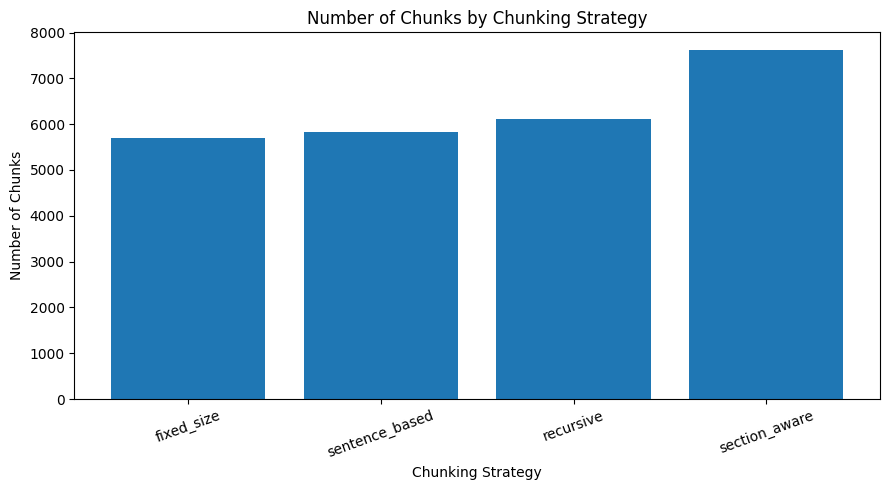

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df['Strategy'],
    comparison_df['Total Chunks']
)

plt.title('Number of Chunks by Chunking Strategy')
plt.xlabel('Chunking Strategy')
plt.ylabel('Number of Chunks')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [20]:
# Load the recursive chunk file as an example
recursive_file = CHUNK_DIR / 'chunks_recursive.jsonl'

recursive_df = pd.read_json(
    recursive_file,
    lines=True
)

print("Loaded chunks:", len(recursive_df))
print("Unique articles:", recursive_df['article_id'].nunique())

# Display selected columns
recursive_df[
    [
        'chunk_id',
        'article_id',
        'title',
        'start_page',
        'end_page',
        'token_count',
        'chunking_strategy'
    ]
].head()

Loaded chunks: 6106
Unique articles: 180


,chunk_id,article_id,title,start_page,end_page,token_count,chunking_strategy
0,recursive_00001,FD_001,Credit card fraud detection in the era of disr...,1,1,497,recursive
1,recursive_00002,FD_001,Credit card fraud detection in the era of disr...,1,1,367,recursive
2,recursive_00003,FD_001,Credit card fraud detection in the era of disr...,1,2,493,recursive
3,recursive_00004,FD_001,Credit card fraud detection in the era of disr...,2,2,472,recursive
4,recursive_00005,FD_001,Credit card fraud detection in the era of disr...,2,3,499,recursive
